# Statistiques descriptives - comparaison des villes sélectionnées à l'ensemble des villes 

La préparation des tables, et la construction des différents indicateurs ont été réalisés sur l'ensemble des villes disponibles dans les données. Néanmoins, nous avons remarqué une part imoportante de villes ayant élu une liste "sans étiquette". Dans la mesure où le caractère « sans étiquette » d'une liste pourrait être corrélé à son orientation politique, il nous semble nécessaire d'opérer un choix méthodologique afin de limiter le biais potentiel qui pourrait en résulter. 

Ainsi, nous avons fait le choix de restreindre l'étude à un sous-échantillon de villes, sélectionnées selon un critère de taille de population, afin de réduire la proportion de communes ayant élu une liste sans étiquette. Le script 3 du dossier data_load_and_prep explique les étapes du choix retenu, à savoir la restriction du champ aux communes de plus de 3500 habitants. L'objectif est ici de rendre explicite le biais induit par cette restriction du champ, plutôt que de conserver un biais potentiel dont les effets sont difficiles à mesurer.

Le script présent permet ainsi de comparer les caractéristiques des villes retenues dans le sous échantillon par rapport à l'ensemble des communes. 

## Chargement et préparation des données

In [ ]:
import numpy as np
import pandas as pd
import os
import s3fs
import seaborn as sns
import matplotlib.pyplot as plt

# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})
BUCKET = "mathildedonnenfeld/diffusion/bistrots_et_bulletins"

FILE_KEY_S3 = "table_analyse_muni.csv"
FILE_PATH_S3 = BUCKET + "/" + FILE_KEY_S3

with fs.open(FILE_PATH_S3, mode="rb") as file_in:
    df = pd.read_csv(file_in, sep=",")

df=df.drop(columns=['Unnamed: 0.1','Unnamed: 0'])

In [ ]:
df['taille_commune'] = np.where(df['POPULATION'] > 3500,
                                      'Plus de 3500 habitants',
                                      "Jusqu'à 3500 habitants")
df["bistrot_dens"] = df["nb_etablissements"] / df["POPULATION"] * 1000
df["tx_abs"] = df["Abstentions"] / df["Inscrits"] 

## Variables démographiques

Dans les nuages de points ci-dessous, on remarque que le sous-échantillon sélectionné présente une distribution de densité de bistrots pour 1000 habitants globalement plus faible que celle observée dans l'échantillon complet. Ce résultat nous semble cohérent : certaines communes, peu peuplées, peuvent avoir un seul bistrot, ce qui génère une densité de bistrot plus élevée. De plus, la distribution des niveaux de vie semble plus resserrée pour les communes de plus de 3 500 habitants que celles de moins de 3 500. Quelques villes de plus de 3 500 habitants présentent des taux de pauvreté plus élevés ; néanmoins, les valeurs sont trop concentrées pour conclure avec précision sur les différences de distribution. Une autre figure est requise pour analyser plus finement cette variable. 

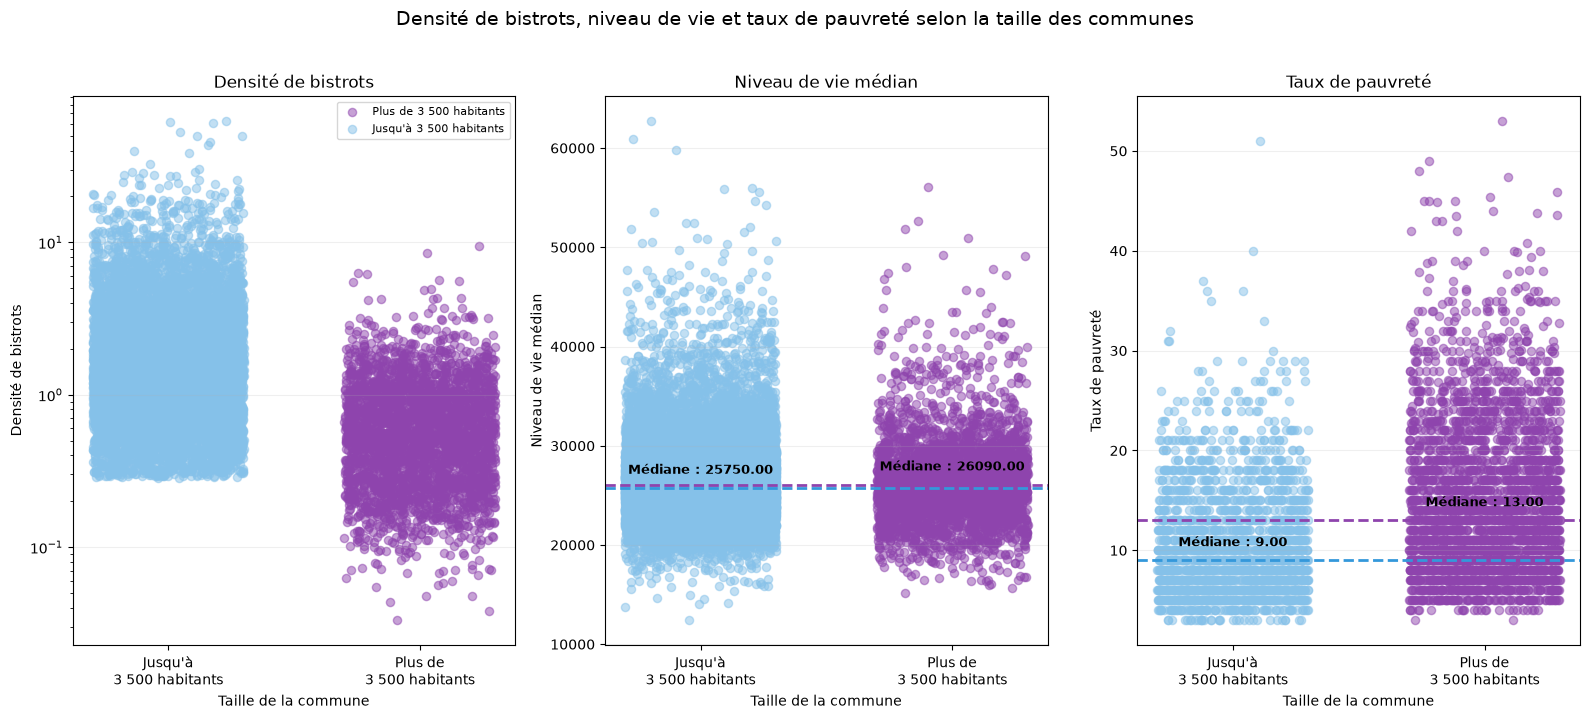

In [46]:
# Séparation des deux groupes
grandes = df[df['taille_commune'] == 'Plus de 3500 habitants']
petites = df[df['taille_commune'] == "Jusqu'à 3500 habitants"]

# Variables
variables = [
    ('bistrot_dens', 'Densité de bistrots'),
    ('NIVVIE_MEDIAN', 'Niveau de vie médian'),
    ('TAUX_PAUVRETE', 'Taux de pauvreté')
]

# 3 graphs sur le même plan 
fig, axes = plt.subplots(1, 3, figsize=(16, 7))

for i, (variable, titre) in enumerate(variables):

    ax = axes[i]

    # Grandes communes
    ax.scatter(
        np.random.uniform(0.7, 1.3, len(grandes)),
        grandes[variable],
        color='#8E44AD',
        alpha=0.5,
        s=35,
        label='Plus de 3 500 habitants'
    )

    # Petites communes
    ax.scatter(
        np.random.uniform(-0.3, 0.3, len(petites)),
        petites[variable],
        color='#85C1E9',
        alpha=0.5,
        s=35,
        label="Jusqu'à 3 500 habitants"
    )

    # Calcul des médianes
    mediane_grandes = grandes[variable].median()
    mediane_petites = petites[variable].median()

    # ajout valeurs 
    if variable != 'bistrot_dens':

        # Lignes horizontales des médianes
        ax.axhline(
            mediane_grandes,
            color='#8E44AD',
            linestyle='--',
            linewidth=2
        )

        ax.axhline(
            mediane_petites,
            color='#3498DB',
            linestyle='--',
            linewidth=2
        )

        # Médiane des petites communes
        ax.annotate(
            f'Médiane : {mediane_petites:.2f}',
            xy=(0, mediane_petites),
            xytext=(0, 8),
            textcoords='offset points',
            color='black',
            fontsize=9,
            fontweight='bold',
            ha='center',
            va='bottom'
        )

        # Médiane des grandes communes
        ax.annotate(
            f'Médiane : {mediane_grandes:.2f}',
            xy=(1, mediane_grandes),
            xytext=(0, 8),
            textcoords='offset points',
            color='black',
            fontsize=9,
            fontweight='bold',
            ha='center',
            va='bottom'
        )

    # Etaler la répartition des bistrots 
    if variable == 'bistrot_dens':
        ax.set_yscale('log')

    # Axe horizontal : taille des communes
    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        "Jusqu'à\n3 500 habitants",
        "Plus de\n3 500 habitants"
    ])

    ax.set_ylabel(titre)
    ax.set_xlabel('Taille de la commune')
    ax.set_title(titre, fontsize=12)

    ax.grid(axis='y', alpha=0.2)

    # Légende 
    if i == 0:
        ax.legend(loc='best', fontsize=8)

# Titre 
fig.suptitle(
    'Densité de bistrots, niveau de vie et taux de pauvreté selon la taille des communes',
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()


Dans le tableau ci-dessous, on observe dans chaque catégorie de commune la répartition des taux de pauvreté. Dans les communes de moins de 3 500 habitants, presque la moitié ont un taux de pauvreté compris entre 5 et 10 %, contre 29 % pour les villes de plus de 3 500 habitants. 22 % des communes de plus de 3 500 habitants présentent un taux de pauvreté supérieur à 20 %, contre seulement 8 % pour les communes de moins de 3 500 habitants. Ainsi, les communes de notre sous-échantillon sont davantage marquées par des taux de pauvreté élevés que les petites communes.




In [47]:
# Discrétisation du taux de pauvreté
bornes = [0, 5, 10, 15, 20, 25, 30, float('inf')]

etiquettes = [
    '0-5 %',
    '5-10 %',
    '10-15 %',
    '15-20 %',
    '20-25 %',
    '25-30 %',
    'Plus de 30 %'
]

df['tranche_pauvrete'] = pd.cut(
    df['TAUX_PAUVRETE'],
    bins=bornes,
    labels=etiquettes,
    right=False
)

# Tableau des pourcentages par catégorie de commune
tableau_pourcentages = pd.crosstab(
    df['taille_commune'],
    df['tranche_pauvrete'],
    normalize='index'
) * 100

tableau = tableau_pourcentages.round()

display(tableau)

tranche_pauvrete,0-5 %,5-10 %,10-15 %,15-20 %,20-25 %,25-30 %,Plus de 30 %
taille_commune,,,,,,,
Jusqu'à 3500 habitants,6.0,47.0,26.0,14.0,5.0,2.0,1.0
Plus de 3500 habitants,1.0,29.0,29.0,18.0,11.0,7.0,5.0


### Âge moyen des bistrots

In [ ]:
df["cat_age_moyen"] = np.trunc(df["age_moyen_bistrots"]).astype("category")

In [ ]:
df.cat_age_moyen.astype("float").describe()

In [ ]:
sns.histplot(data=df, x="cat_age_moyen")

### Niveau de vie 

In [ ]:
df.head()

In [ ]:
df.NIVVIE_MEDIAN.describe()

### Taux de pauvreté

In [ ]:
df.TAUX_PAUVRETE.describe()

In [ ]:
v

### Nombre de candidats selon le tour de l'élection

*Nb : on ne présente ici que le nombre de candidats **au tour final** de l'élection. Par exemple, parmi les villes qui ont eu deux tours, la ville avec le plus de candidats maintenus au second tour en avait 5.*

In [ ]:
df.groupby("tour")["Nombre candidats"].describe()

In [ ]:
sns.countplot(data=df[df['tour']==1], x="Nombre candidats")

In [ ]:
sns.countplot(data=df[df['tour']==2], x="Nombre candidats")

### Indicateur 1

In [ ]:
df["indicateur_vote_attal"] = df["ind1"].astype("category")

In [ ]:
df.indicateur_vote_attal.describe()

In [ ]:
sns.histplot(data=df, x="indicateur_vote_attal")

### Indicateur 2

In [ ]:
df["indicateur_vote_droite"] = df["ind2"].astype("category")

In [ ]:
sns.histplot(data=df, x="indicateur_vote_droite")

### Indicateur 3

In [ ]:
df["indicateur_vote_extreme_droite"] = df["ind3"].astype("category")

In [ ]:
sns.histplot(data=df, x="indicateur_vote_extreme_droite")